# 다음 주 법안 발의량 예측 (SimpleRNN, 10주차 RNN 실습 구조)

10주차 실습은 코로나19 확진자 수로 **다음 날 확진자 수**를 예측했다. 이 노트북은 같은 순서, 같은 함수 이름으로 지난 몇 주의 **국토교통위원회 의원 발의 법안 수**로 **다음 주 발의 법안 수**를 예측한다.

- 숫자는 주별 법안 **건수**만 쓴다. 법안 이름과 의원 이름은 데이터에 없다 (`collect/collect_volume.py`가 건수만 모은다).
- 실습 순서를 그대로 따른 뒤(1~5), 사용자가 요청한 비교를 덧붙인다(6~9).

**순서**: 0 준비 → 1 이해 → 2 데이터 준비 및 전처리 (기간 특성 그래프 먼저) → 3 RNN 입력 데이터 구성 → 4 모델 설계 및 학습 → 5 결과 분석 → 6 기준선 → 7 n(look_back) 4/8/12 실험 → 8 LSTM 비교 → 9 결과표 → 10 화면에 쓰이는 곳

## 0. 준비 (Colab 한글 글꼴 설치)

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('/usr/share/fonts/truetype/nanum'):
    !apt-get -qq install fonts-nanum > /dev/null

In [2]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'   # 컴퓨터가 달라도 결과 차이를 줄인다
os.environ['OMP_NUM_THREADS'] = '1'
import math, json, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
# 실습과 같은 라이브러리: 모델(Sequential, SimpleRNN, Dense, Input), 정규화(MinMaxScaler), 평가(mean_squared_error)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input, LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from IPython.display import Markdown, display

import matplotlib.font_manager as fm
_f = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(_f):
    fm.fontManager.addfont(_f)
    plt.rcParams['font.family'] = fm.FontProperties(fname=_f).get_name()
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
def set_seed(s):
    np.random.seed(s); tf.keras.utils.set_random_seed(s)
set_seed(SEED)
tf.config.experimental.enable_op_determinism()   # 다시 실행해도 같은 결과
tf.config.threading.set_intra_op_parallelism_threads(1); tf.config.threading.set_inter_op_parallelism_threads(1)

## 1. 발의량 예측 인공지능의 이해

| 10주차 실습 | 이 노트북 |
|---|---|
| 하루 단위 코로나19 확진자 수 | **주 단위** 국토교통위원회 의원 발의 법안 수 |
| 과거 3일로 다음 날 예측 (`look_back=3`) | 과거 **n주**로 다음 주 예측 (기본 `look_back=4`, 약 한 달) |
| SimpleRNN(3) + Dense(1), MSE + Adam, 100 epoch, 배치 1 | 같음 |
| 테스트 RMSE, 실제값과 예측값 그래프 | 같음 + **기준선**(지난주 값, 4주 이동평균)과 비교 |

- **주 단위로 묶는 이유**: 하루 단위로 보면 주말·공휴일에는 거의 0건이고 평일에 몰려, 요일 때문에 생기는 오르내림이 대부분이다. 주로 묶으면 요일 효과가 사라진다.
- **국토교통위원회로 정한 이유**: 빼곡이 보는 계류 법안(건축·주거·안전)은 대부분 국토교통위원회 소관이다. 우리 범위(위원회 + 법안 이름 낱말)만 세면 한 주에 몇 건뿐이라 오르내림이 거의 우연이어서, 범위를 넓힌 국토교통위원회 전체를 예측 대상으로 쓴다 (2-2절에서 숫자로 확인).
- **회귀 문제**: 숫자 하나(다음 주 건수)를 맞히므로 정확도가 아니라 **RMSE(건)** 로 평가한다. RMSE 5는 '대략 5건쯤 틀린다'는 뜻이다.
- 발의량은 날씨처럼 저절로 생기는 값이 아니라 국회 일정(임기 시작, 총선, 명절, 휴회)에 크게 흔들린다. 그래서 모델을 만들기 전에 **기간 특성부터 그래프로 본다** (2-2절).

## 2. 데이터 준비 및 전처리
### 2-1. 데이터 불러오기
`data/bill_volume_weekly.csv` (`collect/collect_volume.py`가 열린국회 의원 발의 법률안 목록 API에서 21대·22대 전체 법안을 받아 주별 건수만 남긴 파일)

| 열 | 뜻 |
|---|---|
| week_start | 그 주 월요일 |
| age | 국회 대수 (21, 22) |
| collected_on | 수집한 날. 이 날이 든 주는 아직 끝나지 않은 주 |
| total | 의원 발의 전체 (정부·위원장 제출 법안 없음) |
| committee_empty | 수집한 날까지 소관 위원회가 정해지지 않은(회부 전) 의원 발의 법안 수 |
| 국토교통위원회 | 소관 위원회가 국토교통위원회인 의원 발의 법안 수 |
| scope, scope_molit | 빼곡 범위(위원회 + 법안 이름 낱말, `collect/filter_bills.py`와 같은 규칙) 법안 수, 그 가운데 국토교통위원회 |
| field_1~9, field_na | 22대 범위 법안의 분야별 수 (`data/bills_field_pred.csv`의 자동 분류, 없으면 field_na) |

GitHub 저장소(main)에서 읽고, 안 되면 내려받은 저장소의 `data/` 폴더(또는 NB_LOCAL_DATA)를 읽는다.

In [3]:
BASE = 'https://raw.githubusercontent.com/cbnu-lawmap/law-impact-map/main/data/'

def load(name):
    try:
        return pd.read_csv(BASE + name, encoding='utf-8-sig')
    except Exception:
        for d in [os.environ.get('NB_LOCAL_DATA', ''), '../data', '.']:
            p = os.path.join(d, name)
            if d and os.path.exists(p):
                return pd.read_csv(p, encoding='utf-8-sig')
        from google.colab import files
        print(name, '파일을 올려 주세요'); files.upload()
        return pd.read_csv(name, encoding='utf-8-sig')

raw = load('bill_volume_weekly.csv')
print(raw.shape)
raw.head()

(340, 18)


,week_start,age,collected_on,total,committee_empty,국토교통위원회,scope,scope_molit,field_1,field_2,field_3,field_4,field_5,field_6,field_7,field_8,field_9,field_na
0,2020-06-01,21,2026-11-23,195,5,11,7,5,0,0,0,0,0,0,0,0,0,0
1,2020-06-08,21,2026-11-23,211,0,16,11,7,0,0,0,0,0,0,0,0,0,0
2,2020-06-15,21,2026-11-23,344,1,33,20,12,0,0,0,0,0,0,0,0,0,0
3,2020-06-22,21,2026-11-23,264,0,22,9,8,0,0,0,0,0,0,0,0,0,0
4,2020-06-29,21,2026-11-23,305,0,16,10,8,0,0,0,0,0,0,0,0,0,0


In [4]:
raw['week_start'] = pd.to_datetime(raw['week_start'])
COUNT_COLS = [c for c in raw.columns if c not in ('week_start', 'age', 'collected_on')]
# 21대 마지막 주와 22대 첫 주는 같은 주(2024-05-27 월요일)라 두 줄이 있다 → 주별로 더한다
both = raw.groupby('week_start')['age'].nunique()
print('21·22대가 겹치는 주:', [d.date().isoformat() for d in both[both > 1].index])
weekly = raw.groupby('week_start')[COUNT_COLS].sum().sort_index()

# 끝나지 않은 주(수집한 날이 든 주)는 뺀다. 월요일 + 7일이 수집한 날 이후면 아직 진행 중인 주
collected_on = pd.Timestamp(raw['collected_on'].max())
partial = weekly.index[weekly.index + pd.Timedelta(days=7) > collected_on]
print('수집한 날:', collected_on.date(), '/ 빼는 주(끝나지 않음):', [f"{d.date()} ({int(weekly.loc[d, 'total'])}건까지 셈)" for d in partial])
weekly = weekly.loc[weekly.index + pd.Timedelta(days=7) <= collected_on]
print('남은 주: %d주 (%s ~ %s)' % (len(weekly), weekly.index[0].date(), weekly.index[-1].date()))
print('의원 발의 전체 %d건, 그중 국토교통위원회 %d건 (%.1f%%)' % (weekly.total.sum(), weekly['국토교통위원회'].sum(), 100 * weekly['국토교통위원회'].sum() / weekly.total.sum()))

21·22대가 겹치는 주: ['2024-05-27']
수집한 날: 2026-11-23 / 빼는 주(끝나지 않음): ['2026-11-23 (0건까지 셈)']
남은 주: 338주 (2020-06-01 ~ 2026-11-16)
의원 발의 전체 44750건, 그중 국토교통위원회 3934건 (8.8%)


### 2-2. 기간 특성 먼저 보기
발의량은 국회 일정에 따라 크게 흔들린다. 그래프에 아래를 표시한다 (날짜는 **대략**이며, 휴회 기간은 해마다 달라 경향을 보이기 위한 어림 구간이다).

- **검은 점선**: 22대 국회 임기 시작 (2024-05-30). 21대 임기 끝에 못 다룬 법안이 폐기되고, 새 임기 초에 다시 내는 법안이 몰린다.
- **빨간 점선**: 22대 총선 (2024-04-10). **회색 점선**: 대통령 선거 (2022-03-09, 2025-06-03).
- **주황 칸**: 설·추석 연휴가 든 주.
- **연한 회색 칸**: 여름 휴회 무렵 (7월 말 ~ 8월 중순, 어림). **연한 파랑 칸**: 연말연초 (12월 말 ~ 1월 초, 어림).

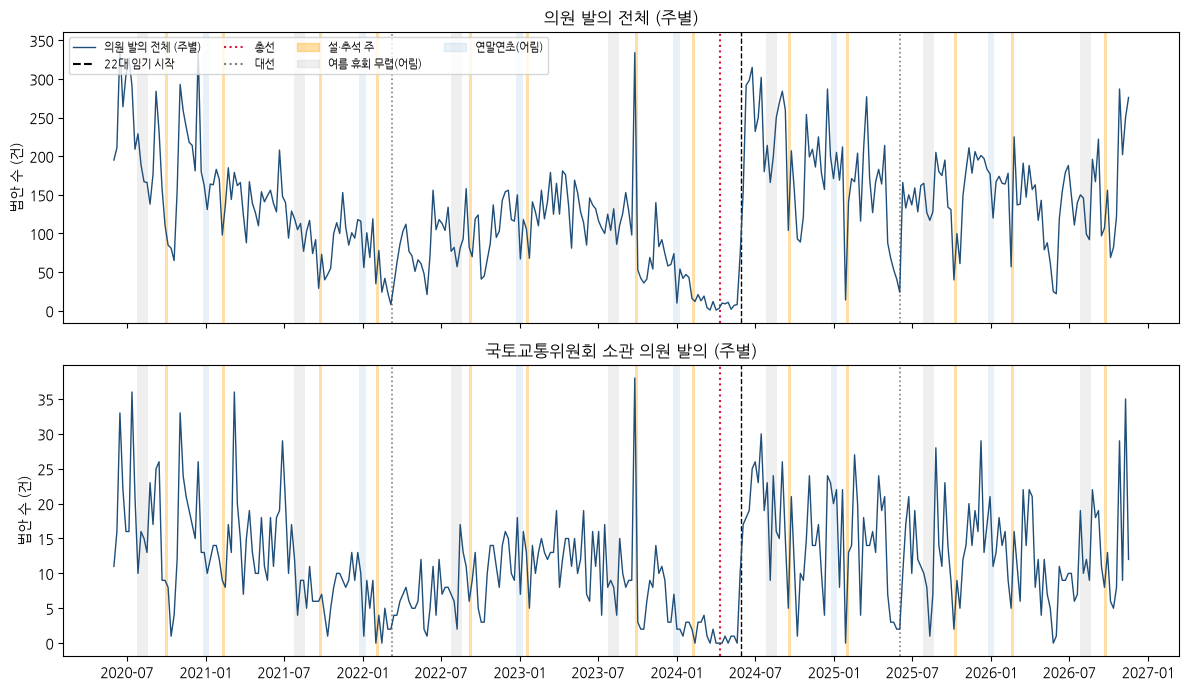

In [5]:
START_22 = pd.Timestamp('2024-05-30')
START_WEEK = START_22 - pd.Timedelta(days=START_22.weekday())   # 임기 시작일이 든 주의 월요일 (2024-05-27)
GENERAL_ELECTION = pd.Timestamp('2024-04-10')
PRESIDENTIAL = [pd.Timestamp('2022-03-09'), pd.Timestamp('2025-06-03')]
SEOLLAL = ['2021-02-12', '2022-02-01', '2023-01-22', '2024-02-10', '2025-01-29', '2026-02-17']
CHUSEOK = ['2020-10-01', '2021-09-21', '2022-09-10', '2023-09-29', '2024-09-17', '2025-10-06', '2026-09-25']
HOLIDAYS = [pd.Timestamp(d) for d in SEOLLAL + CHUSEOK]
YEARS = range(weekly.index[0].year, weekly.index[-1].year + 1)
SUMMER = [(pd.Timestamp(f'{y}-07-25'), pd.Timestamp(f'{y}-08-20')) for y in YEARS]
WINTER = [(pd.Timestamp(f'{y}-12-24'), pd.Timestamp(f'{y + 1}-01-07')) for y in YEARS]

def mark_periods(ax, lo=None, hi=None):
    lo = lo or weekly.index[0]; hi = hi or weekly.index[-1] + pd.Timedelta(days=6)
    inside = lambda d: lo <= d <= hi
    for a, b in SUMMER:
        if inside(a) or inside(b): ax.axvspan(max(a, lo), min(b, hi), color='gray', alpha=0.12, lw=0)
    for a, b in WINTER:
        if inside(a) or inside(b): ax.axvspan(max(a, lo), min(b, hi), color='tab:blue', alpha=0.10, lw=0)
    for d in HOLIDAYS:
        if inside(d):
            ws = d - pd.Timedelta(days=d.weekday())
            ax.axvspan(ws, ws + pd.Timedelta(days=7), color='orange', alpha=0.35, lw=0)
    if inside(START_22): ax.axvline(START_22, color='k', ls='--', lw=1)
    if inside(GENERAL_ELECTION): ax.axvline(GENERAL_ELECTION, color='crimson', ls=':', lw=1.5)
    for d in PRESIDENTIAL:
        if inside(d): ax.axvline(d, color='gray', ls=':', lw=1.2)

def period_legend(ax):
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    h = [Line2D([], [], color='k', ls='--', label='22대 임기 시작'), Line2D([], [], color='crimson', ls=':', label='총선'),
         Line2D([], [], color='gray', ls=':', label='대선'), Patch(color='orange', alpha=0.35, label='설·추석 주'),
         Patch(color='gray', alpha=0.12, label='여름 휴회 무렵(어림)'), Patch(color='tab:blue', alpha=0.10, label='연말연초(어림)')]
    ax.legend(handles=ax.get_legend_handles_labels()[0] + h, fontsize=8, ncol=4, loc='upper left')

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, col, title in [(axes[0], 'total', '의원 발의 전체 (주별)'), (axes[1], '국토교통위원회', '국토교통위원회 소관 의원 발의 (주별)')]:
    mark_periods(ax)
    ax.plot(weekly.index, weekly[col], lw=1, color='#1f4e79', label=title)
    ax.set_ylabel('법안 수 (건)'); ax.set_title(title)
period_legend(axes[0])
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.tight_layout(); plt.show()

In [6]:
# 기간별 주 평균 (그래프에서 본 경향을 숫자로)
ws = weekly.index
we = ws + pd.Timedelta(days=6)
def has_day(days):
    return np.array([any(a <= d <= b for d in days) for a, b in zip(ws, we)])
def overlaps(spans):
    return np.array([any(a <= e and s <= b for s, e in spans) for a, b in zip(ws, we)])

flags = {
    '22대 임기 첫 8주': (ws >= START_WEEK) & (ws < START_WEEK + pd.Timedelta(weeks=8)),
    '21대 임기 마지막 8주 (경계 주 제외)': (ws < START_WEEK) & (ws >= START_WEEK - pd.Timedelta(weeks=8)),
    '21대 임기 마지막 26주 (경계 주 제외)': (ws < START_WEEK) & (ws >= START_WEEK - pd.Timedelta(weeks=26)),
    '총선 전 4주': (ws <= GENERAL_ELECTION) & (ws > GENERAL_ELECTION - pd.Timedelta(weeks=4)),
    '설·추석이 든 주': has_day(HOLIDAYS),
    '여름 휴회 무렵(어림)': overlaps(SUMMER),
    '연말연초(어림)': overlaps(WINTER),
}
period_tab = pd.DataFrame({k: [int(v.sum()), weekly.loc[v, 'total'].mean(), weekly.loc[v, '국토교통위원회'].mean()] for k, v in flags.items()},
                          index=['주 수', '전체 주 평균', '국토교통위원회 주 평균']).T
period_tab.loc['모든 주'] = [len(weekly), weekly.total.mean(), weekly['국토교통위원회'].mean()]
period_tab['주 수'] = period_tab['주 수'].astype(int)
period_tab.round(1)

,주 수,전체 주 평균,국토교통위원회 주 평균
22대 임기 첫 8주,8,239.5,21.0
21대 임기 마지막 8주 (경계 주 제외),8,6.4,0.4
21대 임기 마지막 26주 (경계 주 제외),26,27.0,2.4
총선 전 4주,4,4.2,0.5
설·추석이 든 주,13,87.1,7.9
여름 휴회 무렵(어림),33,138.8,11.3
연말연초(어림),18,127.6,12.2
모든 주,338,132.4,11.6


In [7]:
# 실행 결과 해설 (숫자는 위 표에서 그대로 가져온다)
m = period_tab['국토교통위원회 주 평균']; base = m['모든 주']
def rel(k):
    return f"{m[k]:.1f}건 (평소의 {m[k] / base:.1f}배)"
display(Markdown(
    f"**실행 결과**: 국토교통위원회 의원 발의는 한 주 평균 {base:.1f}건이다. "
    f"22대 임기 첫 8주는 {rel('22대 임기 첫 8주')}, 21대 임기 마지막 8주는 {rel('21대 임기 마지막 8주 (경계 주 제외)')}, "
    f"마지막 26주는 {rel('21대 임기 마지막 26주 (경계 주 제외)')}, 총선 전 4주는 {rel('총선 전 4주')}다. "
    f"설·추석이 든 주는 {rel('설·추석이 든 주')}, 여름 휴회 무렵은 {rel('여름 휴회 무렵(어림)')}, 연말연초는 {rel('연말연초(어림)')}다.\n\n"
    "임기 경계처럼 **한 번만 있는 큰 변화**는 과거 몇 주의 숫자만 보는 모델이 미리 알 수 없다. 명절·휴회처럼 해마다 돌아오는 변화도 "
    "입력이 지난 n주뿐이라 달력을 모르는 모델에게는 갑자기 생기는 일이다. 그래서 이 예측은 '평소 흐름이 이어진다면'의 값으로만 읽는다."))

**실행 결과**: 국토교통위원회 의원 발의는 한 주 평균 11.6건이다. 22대 임기 첫 8주는 21.0건 (평소의 1.8배), 21대 임기 마지막 8주는 0.4건 (평소의 0.0배), 마지막 26주는 2.4건 (평소의 0.2배), 총선 전 4주는 0.5건 (평소의 0.0배)다. 설·추석이 든 주는 7.9건 (평소의 0.7배), 여름 휴회 무렵은 11.3건 (평소의 1.0배), 연말연초는 12.2건 (평소의 1.1배)다.

임기 경계처럼 **한 번만 있는 큰 변화**는 과거 몇 주의 숫자만 보는 모델이 미리 알 수 없다. 명절·휴회처럼 해마다 돌아오는 변화도 입력이 지난 n주뿐이라 달력을 모르는 모델에게는 갑자기 생기는 일이다. 그래서 이 예측은 '평소 흐름이 이어진다면'의 값으로만 읽는다.

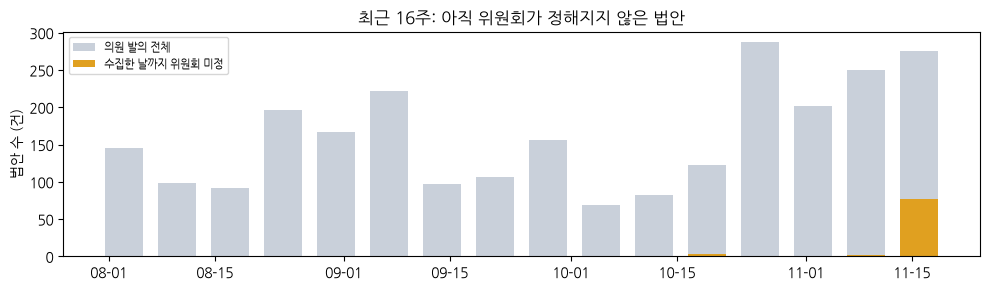

위원회 미정 비율 (최근 8주): 2026-09-28 0%, 2026-10-05 0%, 2026-10-12 0%, 2026-10-19 2%, 2026-10-26 0%, 2026-11-02 0%, 2026-11-09 1%, 2026-11-16 28%
그 이전 모든 주의 위원회 미정 비율: 0.1%


In [8]:
# 최근 주의 '위원회 미정' 법안: 막 낸 법안은 아직 소관 위원회에 회부되지 않아 국토교통위원회 건수에 빠진다
recent = weekly.tail(16)
share = recent['committee_empty'] / recent['total'].where(recent['total'] > 0)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(recent.index, recent['total'], width=5, color='#c9d0da', label='의원 발의 전체')
ax.bar(recent.index, recent['committee_empty'], width=5, color='#e0a020', label='수집한 날까지 위원회 미정')
ax.set_title('최근 16주: 아직 위원회가 정해지지 않은 법안'); ax.set_ylabel('법안 수 (건)'); ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.tight_layout(); plt.show()
print('위원회 미정 비율 (최근 8주):', ', '.join(f"{d.date()} {s:.0%}" for d, s in share.tail(8).items()))
print('그 이전 모든 주의 위원회 미정 비율: %.1f%%' % (100 * weekly['committee_empty'][:-16].sum() / weekly['total'][:-16].sum()))

막 낸 법안은 며칠 뒤 소관 위원회로 회부된다. 회부 전 법안은 어느 위원회 법안인지 모르므로 국토교통위원회 건수에 들어가지 않는다. 그래서 위원회 미정 비율이 높은 마지막 주의 국토교통위원회 건수는 **실제보다 적게** 세어진다.

- 마지막 주들 가운데 미정 비율이 20%를 넘는 주는 **어림 보정**한다: 미정 법안도 그 주에 회부가 끝난 법안과 같은 비율로 국토교통위원회에 갈 것이라고 보고, `국토교통위원회 × 전체 ÷ (전체 − 미정)`을 반올림한다.
- 빼 버리면 가장 최근 주를 잃어 '다음 주' 예측이 한 주 늦어지므로 보정을 골랐다. 보정한 주는 아래에 그대로 출력한다.

In [9]:
MAX_EMPTY = 0.20
fixed = []
for d in weekly.index[::-1][:8]:   # 마지막 8주까지만 본다 (그 이전은 회부가 모두 끝남)
    r = weekly.loc[d]
    if r['total'] > 0 and r['committee_empty'] / r['total'] > MAX_EMPTY:
        est = int(round(r['국토교통위원회'] * r['total'] / (r['total'] - r['committee_empty'])))
        fixed.append((d.date().isoformat(), int(r['국토교통위원회']), est))
        weekly.loc[d, '국토교통위원회'] = est
if fixed:
    for d, a, b in fixed:
        print(f'{d} 주: 위원회 미정 비율이 {100 * MAX_EMPTY:.0f}%를 넘어 국토교통위원회 {a}건 → 어림 보정 {b}건')
else:
    print('마지막 주들의 위원회 미정 비율이 %.0f%% 이하라 보정하지 않는다' % (100 * MAX_EMPTY))
print('학습에 쓰는 마지막 주:', weekly.index[-1].date())

2026-11-16 주: 위원회 미정 비율이 20%를 넘어 국토교통위원회 12건 → 어림 보정 17건
학습에 쓰는 마지막 주: 2026-11-16


빼곡 범위 법안: 주 평균 5.8건 (0건인 주 30/338), 그중 국토교통위원회 주 평균 4.3건


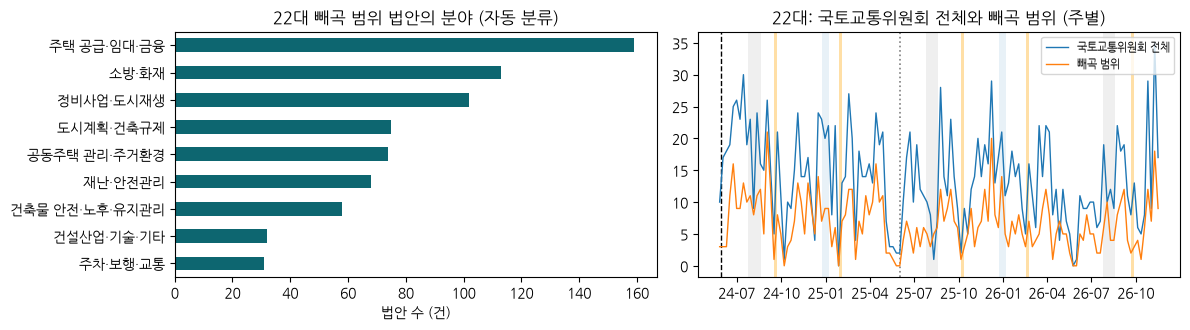

분류 파일(지금 계류 중인 법안만 있음)에 없는 범위 법안(field_na, 이미 처리가 끝난 법안 등): 165건


In [10]:
# 빼곡 범위(위원회 + 법안 이름 낱말)만 세면 한 주에 몇 건인가, 22대 범위 법안은 어느 분야가 많은가
FIELD_NAMES = {1: '소방·화재', 2: '재난·안전관리', 3: '건축물 안전·노후·유지관리', 4: '주택 공급·임대·금융', 5: '공동주택 관리·주거환경',
               6: '정비사업·도시재생', 7: '도시계획·건축규제', 8: '주차·보행·교통', 9: '건설산업·기술·기타'}
print('빼곡 범위 법안: 주 평균 %.1f건 (0건인 주 %d/%d), 그중 국토교통위원회 주 평균 %.1f건'
      % (weekly.scope.mean(), (weekly.scope == 0).sum(), len(weekly), weekly.scope_molit.mean()))
w22 = weekly.loc[weekly.index >= START_WEEK]
fc = pd.Series({FIELD_NAMES[k]: int(w22[f'field_{k}'].sum()) for k in FIELD_NAMES}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
fc.plot.barh(ax=axes[0], color='#0d6670'); axes[0].set_title('22대 빼곡 범위 법안의 분야 (자동 분류)'); axes[0].set_xlabel('법안 수 (건)')
mark_periods(axes[1], w22.index[0], w22.index[-1])
axes[1].plot(w22.index, w22['국토교통위원회'], lw=1, label='국토교통위원회 전체'); axes[1].plot(w22.index, w22['scope'], lw=1, label='빼곡 범위')
axes[1].set_title('22대: 국토교통위원회 전체와 빼곡 범위 (주별)'); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%y-%m'))
plt.tight_layout(); plt.show()
print('분류 파일(지금 계류 중인 법안만 있음)에 없는 범위 법안(field_na, 이미 처리가 끝난 법안 등): %d건' % w22['field_na'].sum())

### 2-3. 예측할 값 고르기와 데이터 구조 확인
실습에서 `usecols=[3]`으로 확진자 수 열만 골랐듯이, 여기서는 `국토교통위원회` 열만 고른다. 행과 열 수를 확인하고 NumPy 실수형 배열로 바꾼다.

In [11]:
TARGET = '국토교통위원회'
df = weekly[[TARGET]]
dates = df.index
print(df.shape)   # (주 수, 1)
dataset = df.values
dataset = dataset.astype('float32')
print(dataset[:5].ravel(), '...', dataset[-5:].ravel())

(338, 1)
[11. 16. 33. 22. 16.] ... [ 8. 29.  9. 35. 17.]


### 2-4. 훈련 데이터와 테스트 데이터 분리
시간 순서가 중요하므로 섞지 않고, **앞쪽 80%를 훈련, 뒤쪽 20%를 테스트**로 쓴다 (과거로 배워 미래를 맞히는 상황).

In [12]:
train_size = int(len(dataset) * 0.8)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size, :], dataset[train_size:len(dataset), :]
print('훈련 %d주 (%s ~ %s)' % (len(train), dates[0].date(), dates[train_size - 1].date()))
print('테스트 %d주 (%s ~ %s)' % (len(test), dates[train_size].date(), dates[-1].date()))

훈련 270주 (2020-06-01 ~ 2025-07-28)
테스트 68주 (2025-08-04 ~ 2026-11-16)


### 2-5. 정규화 (MinMaxScaler)
**훈련 데이터의** 최솟값을 0, 최댓값을 1로 바꾸고, 테스트 데이터에도 **같은 기준**을 쓴다 (테스트 데이터로 기준을 정하면 미래 정보를 미리 보는 셈). 테스트에 훈련 최댓값보다 큰 주가 있으면 1보다 큰 값이 될 수 있다.

In [13]:
scaler = MinMaxScaler(feature_range=(0, 1))
train = scaler.fit_transform(train)
test = scaler.transform(test)
print('훈련 최솟값·최댓값 (건):', scaler.data_min_[0], scaler.data_max_[0])
print('정규화 뒤 범위: 훈련 %.2f~%.2f, 테스트 %.2f~%.2f' % (train.min(), train.max(), test.min(), test.max()))

훈련 최솟값·최댓값 (건): 0.0 38.0
정규화 뒤 범위: 훈련 0.00~1.00, 테스트 0.00~0.92


## 3. RNN 입력 데이터 구성
연속된 n주(`look_back`)를 입력(x), 바로 다음 주를 정답(y)으로 하고, 한 주씩 밀며 학습 데이터를 만든다. 실습의 '과거 3일 → 다음 날'이 여기서는 '과거 4주 → 다음 주'다.

- 첫 번째: 1~4주 → 5주, 두 번째: 2~5주 → 6주, ...
- 실습 코드는 `range(len(dataset) - look_back - 1)`로 마지막 한 개를 버리는데, 여기서는 마지막 한 개까지 쓰도록 `- 1`을 뺐다 (데이터가 주 단위라 한 개도 아깝다).

In [14]:
def create_dataset(dataset, look_back=1):
    x_data, y_data = [], []
    for i in range(len(dataset) - look_back):
        a = dataset[i:(i + look_back), 0]      # 연속된 look_back 주
        x_data.append(a)
        y_data.append(dataset[i + look_back, 0])   # 그다음 주
    return np.array(x_data), np.array(y_data)

In [15]:
look_back = 4
x_train, y_train = create_dataset(train, look_back)
x_test, y_test = create_dataset(test, look_back)
print('x_train', x_train.shape, 'y_train', y_train.shape)
print('x_test', x_test.shape, 'y_test', y_test.shape)

x_train (266, 4) y_train (266,)
x_test (64, 4) y_test (64,)


RNN은 입력을 **(샘플 수, 시간 단계, 특징 수)** 3차원으로 받는다. 4주가 각각 한 시간 단계이고, 각 단계의 특징은 그 주 건수 하나다.

In [16]:
X_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
X_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))
print('X_train', X_train.shape, '/ X_test', X_test.shape)

X_train (266, 4, 1) / X_test (64, 4, 1)


## 4. RNN 모델 설계 및 학습
실습과 같은 구조: `Input(shape=(look_back, 1))` → `SimpleRNN(3)` (뉴런 3개) → `Dense(1)` (다음 주 건수 하나, 선형 출력).
손실 함수는 평균제곱오차(MSE), 옵티마이저는 Adam, `epochs=100`, `batch_size=1` (실습 그대로). 주 단위라 샘플이 수백 개뿐이어서 배치 1로도 시간이 오래 걸리지 않는다.

In [17]:
set_seed(SEED)
model = Sequential([
    Input(shape=(look_back, 1)),
    SimpleRNN(3),
    Dense(1),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19 (76.00 B)

 Trainable params: 19 (76.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(loss='mean_squared_error', optimizer='adam')

In [19]:
history = model.fit(X_train, y_train, epochs=100, batch_size=1, verbose=0)
for e in [0, 9, 19, 49, 99]:
    print('epoch %3d  loss %.4f' % (e + 1, history.history['loss'][e]))

epoch   1  loss 0.0518
epoch  10  loss 0.0267
epoch  20  loss 0.0263
epoch  50  loss 0.0262
epoch 100  loss 0.0261


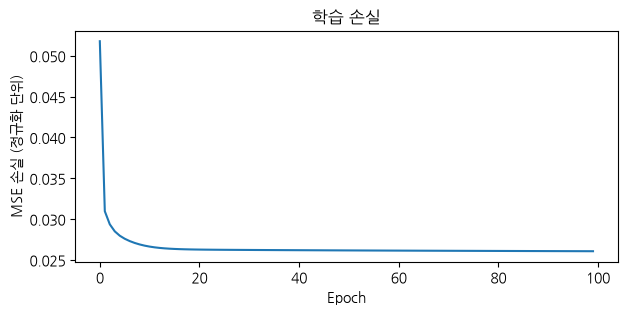

In [20]:
plt.figure(figsize=(7, 3))
plt.plot(history.history['loss'])
plt.xlabel('Epoch'); plt.ylabel('MSE 손실 (정규화 단위)'); plt.title('학습 손실')
plt.show()

## 5. 인공지능 예측 결과 분석
### 5-1. 예측하고 원래 단위(건)로 되돌리기

In [21]:
train_predict = model.predict(X_train, verbose=0)
test_predict = model.predict(X_test, verbose=0)

# 예측값과 정답값을 모두 원래 단위(건)로 복원
train_predict = scaler.inverse_transform(train_predict)
y_train_inv = scaler.inverse_transform([y_train])
test_predict = scaler.inverse_transform(test_predict)
y_test_inv = scaler.inverse_transform([y_test])
print('테스트 첫 5주  실제:', y_test_inv[0][:5].round(1), '/ 예측:', test_predict[:5, 0].round(1))

E0000 00:00:1795431123.400353    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


테스트 첫 5주  실제: [14. 11. 23. 14.  9.] / 예측: [18.3 16.6 14.3 16.9 16. ]


### 5-2. 예측 오차 (RMSE)

In [22]:
train_score = math.sqrt(mean_squared_error(y_train_inv[0], train_predict[:, 0]))
print('Train RMSE: %.2f 건' % train_score)
test_score = math.sqrt(mean_squared_error(y_test_inv[0], test_predict[:, 0]))
print('Test RMSE: %.2f 건' % test_score)

Train RMSE: 6.15 건
Test RMSE: 6.62 건


### 5-3. 실제값과 예측값 비교 그래프

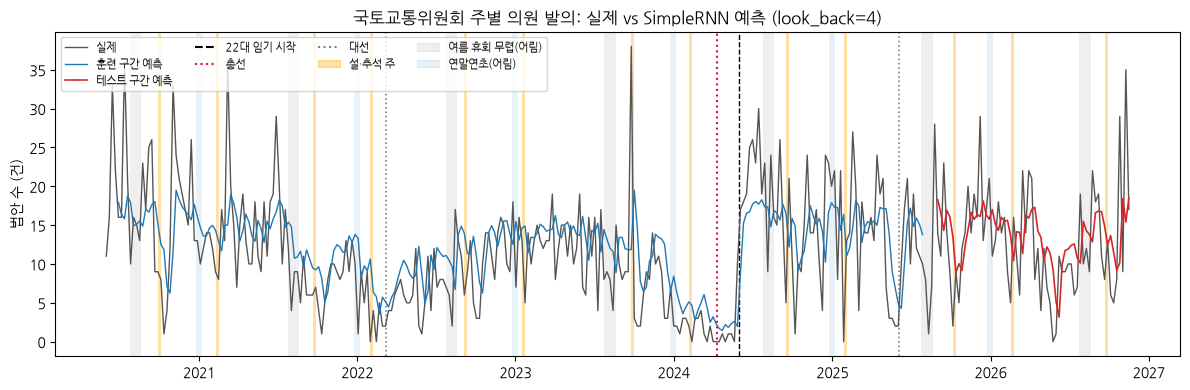

In [23]:
# 원본과 같은 크기의 배열을 NaN으로 채우고, 예측한 주 위치에만 값을 넣는다
train_predict_plot = np.full_like(dataset, np.nan)
train_predict_plot[look_back:len(train_predict) + look_back, :] = train_predict
test_predict_plot = np.full_like(dataset, np.nan)
test_predict_plot[len(train) + look_back:len(dataset), :] = test_predict

fig, ax = plt.subplots(figsize=(12, 4))
mark_periods(ax)
ax.plot(dates, dataset, color='#555', lw=1, label='실제')
ax.plot(dates, train_predict_plot, color='tab:blue', lw=1, label='훈련 구간 예측')
ax.plot(dates, test_predict_plot, color='tab:red', lw=1.2, label='테스트 구간 예측')
ax.set_ylabel('법안 수 (건)'); ax.set_title(f'국토교통위원회 주별 의원 발의: 실제 vs SimpleRNN 예측 (look_back={look_back})')
period_legend(ax)
plt.tight_layout(); plt.show()

In [24]:
c_same = np.corrcoef(test_predict[1:, 0], y_test_inv[0][1:])[0, 1]
c_prev = np.corrcoef(test_predict[1:, 0], y_test_inv[0][:-1])[0, 1]
display(Markdown(
    f"**실행 결과**: 훈련 RMSE {train_score:.2f}건, 테스트 RMSE {test_score:.2f}건. 테스트 기간 실제 주 평균은 {y_test_inv[0].mean():.1f}건, "
    f"표준편차는 {y_test_inv[0].std():.1f}건이다. 예측과 **같은 주** 실제값의 상관계수는 {c_same:.2f}, **한 주 전** 실제값과의 상관계수는 {c_prev:.2f}다. "
    + ("예측이 한 주 전 값과 더 닮아, 큰 오르내림을 미리 맞히기보다 한 주 늦게 따라가는 편이다. " if c_prev > c_same else
       "예측이 한 주 전 값보다 같은 주 값과 더 닮았다. ")
    + "이 숫자만으로는 좋은지 나쁜지 알 수 없어서, 6절에서 아주 단순한 방법(기준선)과 비교한다."))

**실행 결과**: 훈련 RMSE 6.15건, 테스트 RMSE 6.62건. 테스트 기간 실제 주 평균은 12.8건, 표준편차는 6.8건이다. 예측과 **같은 주** 실제값의 상관계수는 0.31, **한 주 전** 실제값과의 상관계수는 0.86다. 예측이 한 주 전 값과 더 닮아, 큰 오르내림을 미리 맞히기보다 한 주 늦게 따라가는 편이다. 이 숫자만으로는 좋은지 나쁜지 알 수 없어서, 6절에서 아주 단순한 방법(기준선)과 비교한다.

## 6. 기준선과 비교
모델이 쓸모 있으려면 **누구나 바로 할 수 있는 단순한 예측**보다 나아야 한다. 같은 테스트 정답 주에 대해 두 기준선의 RMSE를 구한다.

- **지난주 값**: 다음 주도 이번 주와 같다고 본다.
- **4주 이동평균**: 최근 4주 평균이 다음 주 값이라고 본다.

둘 다 테스트 구간 안의 값만 써서, 모델이 보는 정보(테스트 구간의 지난 n주)와 같다.

In [25]:
def baselines(series, start, look_back):
    # series: 원래 단위(건) 1차원 배열, start: 테스트 시작 위치. 정답은 series[start + look_back:] (모델과 같은 주)
    idx = np.arange(start + look_back, len(series))
    y = series[idx]
    naive = series[idx - 1]
    ma4 = np.array([series[i - 4:i].mean() for i in idx])
    return y, naive, ma4

def rmse(a, b):
    return math.sqrt(mean_squared_error(a, b))

series = dataset[:, 0]
y_b, naive_pred, ma4_pred = baselines(series, train_size, look_back)
assert np.allclose(y_b, y_test_inv[0], atol=1e-3), '기준선과 모델의 정답 주가 다름'
base_scores = {'SimpleRNN (look_back=%d)' % look_back: test_score, '지난주 값': rmse(y_b, naive_pred), '4주 이동평균': rmse(y_b, ma4_pred)}
pd.Series(base_scores, name='테스트 RMSE (건)').round(2).to_frame()

,테스트 RMSE (건)
SimpleRNN (look_back=4),6.62
지난주 값,8.72
4주 이동평균,7.00


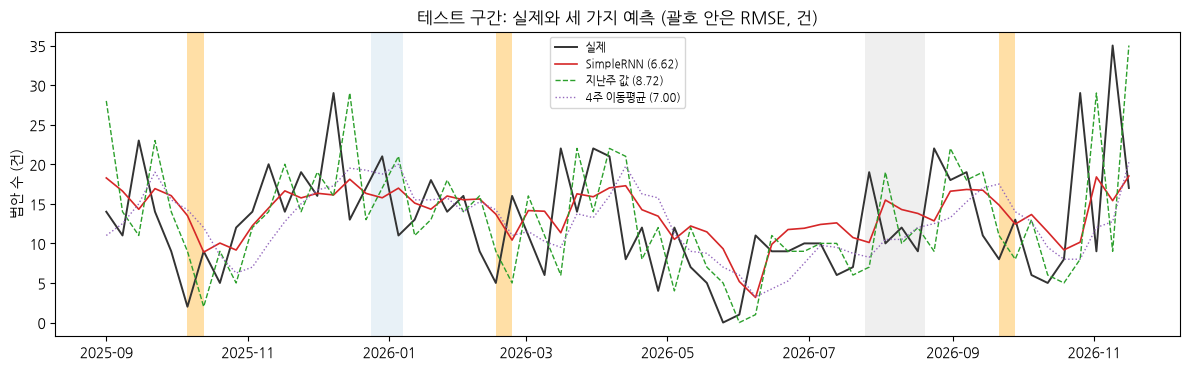

In [26]:
td = dates[train_size + look_back:]
fig, ax = plt.subplots(figsize=(12, 3.8))
mark_periods(ax, td[0], td[-1])
ax.plot(td, y_b, color='#333', lw=1.4, label='실제')
ax.plot(td, test_predict[:, 0], color='tab:red', lw=1.2, label=f'SimpleRNN ({test_score:.2f})')
ax.plot(td, naive_pred, color='tab:green', lw=1, ls='--', label=f'지난주 값 ({base_scores["지난주 값"]:.2f})')
ax.plot(td, ma4_pred, color='tab:purple', lw=1, ls=':', label=f'4주 이동평균 ({base_scores["4주 이동평균"]:.2f})')
ax.set_title('테스트 구간: 실제와 세 가지 예측 (괄호 안은 RMSE, 건)'); ax.set_ylabel('법안 수 (건)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [27]:
best_base = min(['지난주 값', '4주 이동평균'], key=lambda k: base_scores[k])
gap = test_score - base_scores[best_base]
display(Markdown(
    f"**실행 결과**: SimpleRNN 테스트 RMSE {test_score:.2f}건, 지난주 값 {base_scores['지난주 값']:.2f}건, 4주 이동평균 {base_scores['4주 이동평균']:.2f}건. "
    + (f"SimpleRNN이 가장 나은 기준선({best_base})보다 {-gap:.2f}건 작다. 테스트 {len(y_b)}주로 잰 값이라 차이가 1건 안팎이면 우연일 수 있다."
       if gap < 0 else
       f"**기준선({best_base})이 SimpleRNN보다 {gap:.2f}건 낫다.** 발의량은 국회 일정 때문에 갑자기 뛰고 꺼지는데, 지난 몇 주 숫자만 보는 작은 RNN은 "
       "이 변화를 미리 알 수 없어 결국 최근 평균 근처를 내놓는다. 이 결과는 그대로 기록한다.")))

**실행 결과**: SimpleRNN 테스트 RMSE 6.62건, 지난주 값 8.72건, 4주 이동평균 7.00건. SimpleRNN이 가장 나은 기준선(4주 이동평균)보다 0.38건 작다. 테스트 64주로 잰 값이라 차이가 1건 안팎이면 우연일 수 있다.

## 7. n(look_back) 4 / 8 / 12 실험
과거를 몇 주 보느냐에 따라 달라지는지 본다. 신경망은 시작 가중치(시드)에 따라 결과가 흔들리므로 **시드 3개**로 학습해 평균과 표준편차를 낸다. 기준선도 n마다 정답 주가 달라지므로(테스트 앞부분 n주는 입력으로만 쓰임) 같은 정답 주로 다시 잰다.
구조·학습 설정은 4절과 같다 (SimpleRNN(3), Dense(1), MSE, Adam, 100 epoch, 배치 1).

In [28]:
def run_rnn(data, look_back, seed, cell=SimpleRNN, units=3):
    # 2~5절과 같은 과정을 한 번에: 80/20 분리 → 훈련 기준 정규화 → create_dataset → 학습 → 건 단위 테스트 RMSE
    set_seed(seed)
    size = int(len(data) * 0.8)
    tr, te = data[0:size, :], data[size:len(data), :]
    sc = MinMaxScaler(feature_range=(0, 1))
    tr = sc.fit_transform(tr); te = sc.transform(te)
    xtr, ytr = create_dataset(tr, look_back); xte, yte = create_dataset(te, look_back)
    xtr = np.reshape(xtr, (xtr.shape[0], xtr.shape[1], 1)); xte = np.reshape(xte, (xte.shape[0], xte.shape[1], 1))
    m = Sequential([Input(shape=(look_back, 1)), cell(units), Dense(1)])
    m.compile(loss='mean_squared_error', optimizer='adam')
    m.fit(xtr, ytr, epochs=100, batch_size=1, verbose=0)
    p = sc.inverse_transform(m.predict(xte, verbose=0))[:, 0]
    y = sc.inverse_transform(yte.reshape(-1, 1))[:, 0]
    return rmse(y, p), p, y

SEEDS = [42, 7, 2026]
LOOK_BACKS = [4, 8, 12]
exp_rows = []
for n in LOOK_BACKS:
    scores = [run_rnn(dataset, n, s)[0] for s in SEEDS]
    y_n, nv, ma = baselines(series, train_size, n)
    exp_rows.append({'look_back': n, '테스트 주 수': len(y_n), 'SimpleRNN 평균': np.mean(scores), 'SimpleRNN 표준편차': np.std(scores),
                     '시드별': ' / '.join(f'{s:.2f}' for s in scores), '지난주 값': rmse(y_n, nv), '4주 이동평균': rmse(y_n, ma)})
    print(f'look_back={n}: 시드별 RMSE', exp_rows[-1]['시드별'])
exp = pd.DataFrame(exp_rows).set_index('look_back')
exp.round(2)

look_back=4: 시드별 RMSE 6.62 / 6.62 / 6.68


E0000 00:00:1795431247.628746    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795431280.983136    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795431314.498030    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


look_back=8: 시드별 RMSE 6.70 / 6.73 / 6.77


E0000 00:00:1795431350.648997    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795431386.769859    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


look_back=12: 시드별 RMSE 6.73 / 6.71 / 6.83


E0000 00:00:1795431422.509306    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,테스트 주 수,SimpleRNN 평균,SimpleRNN 표준편차,시드별,지난주 값,4주 이동평균
look_back,,,,,,
4,64,6.64,0.03,6.62 / 6.62 / 6.68,8.72,7.00
8,60,6.74,0.03,6.70 / 6.73 / 6.77,8.60,7.12
12,56,6.76,0.05,6.73 / 6.71 / 6.83,8.76,7.10


In [29]:
best_n = int(exp['SimpleRNN 평균'].idxmin())
lines = []
for n, r in exp.iterrows():
    b = min(r['지난주 값'], r['4주 이동평균'])
    lines.append(f"- look_back={n}: SimpleRNN {r['SimpleRNN 평균']:.2f}±{r['SimpleRNN 표준편차']:.2f}건, 더 나은 기준선 {b:.2f}건 → "
                 + ("SimpleRNN이 낫다" if r['SimpleRNN 평균'] < b else "**기준선이 낫다**"))
display(Markdown(
    f"**실행 결과**: 시드 3개 평균으로 가장 작은 RMSE는 look_back={best_n}다.\n\n" + '\n'.join(lines) + "\n\n"
    + ("look_back을 늘릴수록 RMSE가 줄었다. " if exp['SimpleRNN 평균'].is_monotonic_decreasing else "look_back을 늘린다고 RMSE가 꼬박꼬박 줄지는 않았다. ")
    + "다만 n마다 정답 주가 달라(길게 보면 테스트 앞부분이 입력으로 더 빠짐) n끼리 직접 비교하기보다 같은 줄의 기준선과의 차이를 함께 봐야 한다."))

**실행 결과**: 시드 3개 평균으로 가장 작은 RMSE는 look_back=4다.

- look_back=4: SimpleRNN 6.64±0.03건, 더 나은 기준선 7.00건 → SimpleRNN이 낫다
- look_back=8: SimpleRNN 6.74±0.03건, 더 나은 기준선 7.12건 → SimpleRNN이 낫다
- look_back=12: SimpleRNN 6.76±0.05건, 더 나은 기준선 7.10건 → SimpleRNN이 낫다

look_back을 늘린다고 RMSE가 꼬박꼬박 줄지는 않았다. 다만 n마다 정답 주가 달라(길게 보면 테스트 앞부분이 입력으로 더 빠짐) n끼리 직접 비교하기보다 같은 줄의 기준선과의 차이를 함께 봐야 한다.

## 8. LSTM 비교 (한 칸)
SimpleRNN을 LSTM(3)으로만 바꾸고 나머지는 4절과 같게 둔다 (look_back=4, 같은 시드).

In [30]:
lstm_score, _, _ = run_rnn(dataset, 4, SEED, cell=LSTM)
print('LSTM(3) look_back=4 테스트 RMSE: %.2f 건 (같은 시드 SimpleRNN %.2f 건)' % (lstm_score, test_score))

LSTM(3) look_back=4 테스트 RMSE: 6.59 건 (같은 시드 SimpleRNN 6.62 건)


### 8-2. 곁가지: 의원 발의 전체로 해 보면
같은 방법(SimpleRNN, look_back=4, 한 시드)을 국토교통위원회가 아니라 **의원 발의 전체** 주별 건수에 써 본다. 위원회 미정 문제(2-2절)가 없는 대신, 숫자가 훨씬 크다.

In [31]:
total_data = weekly[['total']].values.astype('float32')
total_score, _, _ = run_rnn(total_data, 4, SEED)
ty, tnv, tma = baselines(total_data[:, 0], int(len(total_data) * 0.8), 4)
total_row = {'SimpleRNN': total_score, '지난주 값': rmse(ty, tnv), '4주 이동평균': rmse(ty, tma), '테스트 주 평균': float(ty.mean())}
print('의원 발의 전체 테스트 RMSE (건):', {k: round(v, 2) for k, v in total_row.items()})

의원 발의 전체 테스트 RMSE (건): {'SimpleRNN': 49.96, '지난주 값': 55.91, '4주 이동평균': 56.47, '테스트 주 평균': 149.42}


## 9. 결과표

In [32]:
rows = [(f'SimpleRNN look_back={n} (시드 3개 평균±표준편차)', f"{r['SimpleRNN 평균']:.2f} ± {r['SimpleRNN 표준편차']:.2f}", int(r['테스트 주 수']),
         f"{r['지난주 값']:.2f}", f"{r['4주 이동평균']:.2f}") for n, r in exp.iterrows()]
rows.append(('LSTM look_back=4 (시드 42)', f'{lstm_score:.2f}', int(exp.loc[4, '테스트 주 수']), f"{exp.loc[4, '지난주 값']:.2f}", f"{exp.loc[4, '4주 이동평균']:.2f}"))
md_t = ['| 모델 | 테스트 RMSE (건) | 테스트 주 수 | 같은 주 지난주 값 | 같은 주 4주 이동평균 |', '|---|---|---|---|---|']
md_t += [f'| {a} | {b} | {c} | {d} | {e} |' for a, b, c, d, e in rows]

wins = [n for n, r in exp.iterrows() if r['SimpleRNN 평균'] < min(r['지난주 값'], r['4주 이동평균'])]
notes = [
    f"대상: 국토교통위원회 소관 의원 발의 법안 수 (주별, {len(weekly)}주, {weekly.index[0].date()} ~ {weekly.index[-1].date()}). 테스트는 뒤쪽 20%({len(test)}주) 가운데 첫 n주를 뺀 주.",
    ("SimpleRNN(시드 평균)이 같은 주의 더 나은 기준선보다 나은 n: " + ', '.join(map(str, wins)) + ". 다만 차이가 1건 안팎이면 테스트 주가 적어 우연일 수 있다.") if wins else
    "**어느 n에서도 SimpleRNN이 단순한 기준선(지난주 값 또는 4주 이동평균)을 이기지 못했다.** 발의량의 큰 변화는 국회 일정에서 오는데 모델 입력에는 일정이 없다.",
    f"LSTM은 {lstm_score:.2f}건으로 같은 시드 SimpleRNN({test_score:.2f}건)보다 " + ("작다" if lstm_score < test_score else "크거나 같다")
    + (" (차이 0.5건 미만). " if abs(lstm_score - test_score) < 0.5 else ". ") + "입력이 지난 몇 주 건수뿐이면 층을 바꿔도 알 수 있는 정보는 같다.",
    f"의원 발의 전체(곁가지): SimpleRNN {total_row['SimpleRNN']:.2f}건, 지난주 값 {total_row['지난주 값']:.2f}건, 4주 이동평균 {total_row['4주 이동평균']:.2f}건 (테스트 주 평균 {total_row['테스트 주 평균']:.1f}건).",
    "그래서 화면에서는 이 예측을 **참고용**으로만 보여 주고, 지난주 값 기준선 RMSE를 바로 옆에 함께 적는다.",
]
display(Markdown('\n'.join(md_t) + '\n\n' + '\n'.join('- ' + n for n in notes)))

| 모델 | 테스트 RMSE (건) | 테스트 주 수 | 같은 주 지난주 값 | 같은 주 4주 이동평균 |
|---|---|---|---|---|
| SimpleRNN look_back=4 (시드 3개 평균±표준편차) | 6.64 ± 0.03 | 64 | 8.72 | 7.00 |
| SimpleRNN look_back=8 (시드 3개 평균±표준편차) | 6.74 ± 0.03 | 60 | 8.60 | 7.12 |
| SimpleRNN look_back=12 (시드 3개 평균±표준편차) | 6.76 ± 0.05 | 56 | 8.76 | 7.10 |
| LSTM look_back=4 (시드 42) | 6.59 | 64 | 8.72 | 7.00 |

- 대상: 국토교통위원회 소관 의원 발의 법안 수 (주별, 338주, 2020-06-01 ~ 2026-11-16). 테스트는 뒤쪽 20%(68주) 가운데 첫 n주를 뺀 주.
- SimpleRNN(시드 평균)이 같은 주의 더 나은 기준선보다 나은 n: 4, 8, 12. 다만 차이가 1건 안팎이면 테스트 주가 적어 우연일 수 있다.
- LSTM은 6.59건으로 같은 시드 SimpleRNN(6.62건)보다 작다 (차이 0.5건 미만). 입력이 지난 몇 주 건수뿐이면 층을 바꿔도 알 수 있는 정보는 같다.
- 의원 발의 전체(곁가지): SimpleRNN 49.96건, 지난주 값 55.91건, 4주 이동평균 56.47건 (테스트 주 평균 149.4건).
- 그래서 화면에서는 이 예측을 **참고용**으로만 보여 주고, 지난주 값 기준선 RMSE를 바로 옆에 함께 적는다.

숫자는 시드·스레드를 고정해 같은 컴퓨터에서는 똑같이 나오지만, GitHub Actions가 고르는 CPU 종류에 따라 셋째 자리가 조금 달라질 수 있다. 그래서 위 결과표와 해설은 직접 적지 않고 **실행한 숫자로 코드가 만든다**.

## 10. 화면에 쓰이는 곳
관리자 화면 상황판에 **"다음 주 예상 발의량 (국토교통위원회)"** 카드를 둔다.

- 다음 주 예측은 7절에서 시드 평균 RMSE가 가장 작았던 look_back으로, **모든 주(훈련 + 테스트)** 를 써서 같은 구조를 다시 학습한 모델로 낸다. 테스트 구간은 성능을 재는 데만 쓰고 끝났으므로, 실제로 내다볼 때는 가장 최근 흐름까지 배운 모델이 낫기 때문이다. 정규화 기준도 모든 주로 다시 정한다.
- look_back을 테스트 결과로 골랐으므로 화면에 적는 테스트 RMSE는 실제보다 조금 좋게 나온 값일 수 있다.
- 예측하는 주는 마지막으로 쓴 주의 바로 다음 주다. 수집한 날이 월요일이면 그 주(수집한 날이 든 주) 전체가 된다.
- 내보내는 파일: `web/data/models/bill_volume_rnn.json` (최근 26주 실제 건수, 다음 주 예측, 자료 기준일, SimpleRNN·기준선 테스트 RMSE, look_back). 신경망 가중치는 넣지 않는다 (화면은 숫자만 보여 줌).
- 카드에는 "예측·참고용"과 자료 기준일을 함께 적는다. 국회 일정(임기 시작, 명절, 휴회)을 모델이 모르므로 그런 주에는 크게 빗나갈 수 있다.

In [33]:
LB = best_n
set_seed(SEED)
scaler_all = MinMaxScaler(feature_range=(0, 1))
all_scaled = scaler_all.fit_transform(dataset)
x_all, y_all = create_dataset(all_scaled, LB)
X_all = np.reshape(x_all, (x_all.shape[0], x_all.shape[1], 1))
final = Sequential([Input(shape=(LB, 1)), SimpleRNN(3), Dense(1)])
final.compile(loss='mean_squared_error', optimizer='adam')
final.fit(X_all, y_all, epochs=100, batch_size=1, verbose=0)

last = np.reshape(all_scaled[-LB:], (1, LB, 1))   # 가장 최근 LB주
next_pred = float(max(0.0, scaler_all.inverse_transform(final.predict(last, verbose=0))[0, 0]))
next_week = dates[-1] + pd.Timedelta(days=7)
print('다음 주(%s 월요일 시작) 예상: %.1f건 / 지난주 값 기준선: %d건' % (next_week.date(), next_pred, int(series[-1])))

r = exp.loc[LB]
info = {
    'name': 'bill_volume_rnn',
    'target': '국토교통위원회 소관 의원 발의 법안 수 (주별, 월요일 시작)',
    'model': f'SimpleRNN(3) + Dense(1), 지난 {LB}주로 다음 주 예측, 모든 주로 다시 학습',
    'look_back': LB,
    'data_cutoff': (dates[-1] + pd.Timedelta(days=6)).date().isoformat(),   # 마지막으로 쓴 주의 일요일
    'collected_on': collected_on.date().isoformat(),
    'recent': [{'week_start': d.date().isoformat(), 'count': int(v)} for d, v in zip(dates[-26:], series[-26:])],
    'forecast': {'week_start': next_week.date().isoformat(), 'count': round(next_pred, 1)},
    'rmse': {'simple_rnn': round(float(r['SimpleRNN 평균']), 2), 'naive_last_week': round(float(r['지난주 값']), 2),
             'moving_avg_4': round(float(r['4주 이동평균']), 2), 'lstm_look_back_4': round(float(lstm_score), 2)},
    'rmse_note': f"테스트(뒤쪽 20%, {int(r['테스트 주 수'])}주) RMSE, 건. SimpleRNN은 시드 3개 평균. 기준선은 같은 주로 잼",
    'adjusted_weeks': [{'week_start': d, 'counted': a, 'estimated': b} for d, a, b in fixed],
    'n_weeks': int(len(dates)),
    'trained_at': datetime.date.today().isoformat(),
}
model_dir = '../web/data/models' if os.path.isdir('../web/data') else '.'
os.makedirs(model_dir, exist_ok=True)
with open(os.path.join(model_dir, 'bill_volume_rnn.json'), 'w', encoding='utf-8') as f:
    json.dump(info, f, ensure_ascii=False, indent=1)
print(json.dumps({k: v for k, v in info.items() if k != 'recent'}, ensure_ascii=False, indent=1))

다음 주(2026-11-23 월요일 시작) 예상: 17.9건 / 지난주 값 기준선: 17건
{
 "name": "bill_volume_rnn",
 "target": "국토교통위원회 소관 의원 발의 법안 수 (주별, 월요일 시작)",
 "model": "SimpleRNN(3) + Dense(1), 지난 4주로 다음 주 예측, 모든 주로 다시 학습",
 "look_back": 4,
 "data_cutoff": "2026-11-22",
 "collected_on": "2026-11-23",
 "forecast": {
  "week_start": "2026-11-23",
  "count": 17.9
 },
 "rmse": {
  "simple_rnn": 6.64,
  "naive_last_week": 8.72,
  "moving_avg_4": 7.0,
  "lstm_look_back_4": 6.59
 },
 "rmse_note": "테스트(뒤쪽 20%, 64주) RMSE, 건. SimpleRNN은 시드 3개 평균. 기준선은 같은 주로 잼",
 "adjusted_weeks": [
  {
   "week_start": "2026-11-16",
   "counted": 12,
   "estimated": 17
  }
 ],
 "n_weeks": 338,
 "trained_at": "2026-11-23"
}


E0000 00:00:1795431525.120977    2590 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


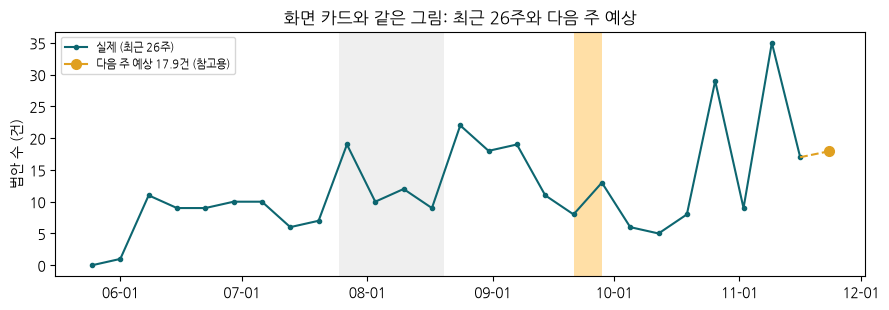

In [34]:
rd = dates[-26:]
fig, ax = plt.subplots(figsize=(9, 3.2))
mark_periods(ax, rd[0], next_week + pd.Timedelta(days=6))
ax.plot(rd, series[-26:], marker='o', ms=3, color='#0d6670', label='실제 (최근 26주)')
ax.plot([rd[-1], next_week], [series[-1], next_pred], ls='--', color='#e0a020')
ax.plot([next_week], [next_pred], marker='o', ms=7, color='#e0a020', label=f'다음 주 예상 {next_pred:.1f}건 (참고용)')
ax.set_title('화면 카드와 같은 그림: 최근 26주와 다음 주 예상'); ax.set_ylabel('법안 수 (건)'); ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.tight_layout(); plt.show()